## 1. Import Libraries

Import the libraries required for data analysis and text processing.

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import spacy

from langdetect import detect


## 2. Load Dataset

Load the CSV file

In [2]:
df = pd.read_csv("df_file.csv")

In [3]:
df.head()

,Text,Label
0,Budget to set scene for election\n \n Gordon B...,0
1,Army chiefs in regiments decision\n \n Militar...,0
2,Howard denies split over ID cards\n \n Michael...,0
3,Observers to monitor UK election\n \n Minister...,0
4,Kilroy names election seat target\n \n Ex-chat...,0


In [4]:
df.tail()

,Text,Label
2220,India opens skies to competition\n \n India wi...,4
2221,Yukos bankruptcy 'not US matter'\n \n Russian ...,4
2222,Survey confirms property slowdown\n \n Governm...,4
2223,High fuel prices hit BA's profits\n \n British...,4
2224,US trade gap hits record in 2004\n \n The gap ...,4


## 3. Dataset Overview

Explore the basic structure and information of the dataset.

In [5]:
df.shape

(2225, 2)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Text    2225 non-null   str  
 1   Label   2225 non-null   int64
dtypes: int64(1), str(1)
memory usage: 34.9 KB


In [7]:
df.dtypes

Text       str
Label    int64
dtype: object

In [8]:
df.isnull().sum()

Text     0
Label    0
dtype: int64

In [9]:
df.describe(include="all")

,Text,Label
count,2225,2225.000000
unique,2127,NaN
top,Howard denies split over ID cards\n \n Michael...,NaN
freq,2,NaN
mean,NaN,2.027416
std,NaN,1.438694
min,NaN,0.000000
25%,NaN,1.000000
50%,NaN,2.000000
75%,NaN,3.000000


## 4. Label Analysis

Analyze the distribution of the target labels.

In [10]:
df["Label"].value_counts()

Label
1    511
4    510
0    417
2    401
3    386
Name: count, dtype: int64

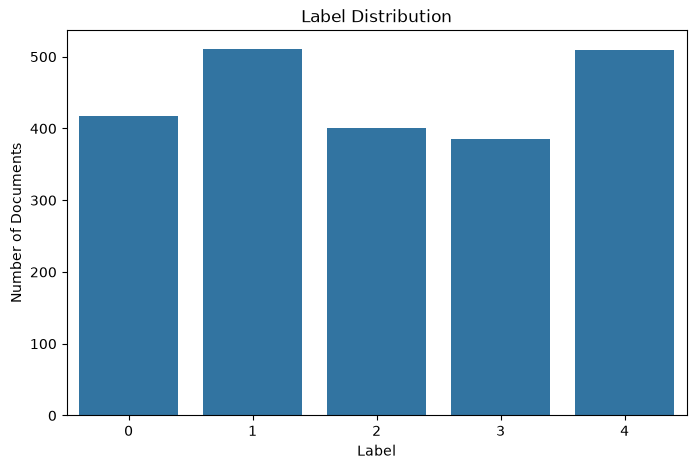

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Label")

plt.title("Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Documents")

plt.show()

In [12]:
label_percentage = df["Label"].value_counts(normalize=True) * 100

label_percentage.sort_index()

Label
0    18.741573
1    22.966292
2    18.022472
3    17.348315
4    22.921348
Name: proportion, dtype: float64

## 5. Text Statistics

Analyze the length and structure of the text documents.

In [13]:
df["Character_Length"] = df["Text"].str.len()

df["Word_Count"] = df["Text"].str.split().str.len()

df[["Character_Length", "Word_Count"]].describe()

,Character_Length,Word_Count
count,2225.000000,2225.000000
mean,2275.363596,384.040449
std,1370.782663,238.174497
min,507.000000,89.000000
25%,1455.000000,246.000000
50%,1979.000000,332.000000
75%,2815.000000,471.000000
max,25597.000000,4432.000000


In [14]:
print("Shortest Document:")
print(df.loc[df["Character_Length"].idxmin(), "Text"])

print("\nLongest Document:")
print(df.loc[df["Character_Length"].idxmax(), "Text"])

Shortest Document:
Blunkett hints at election call
 
 Ex-Home Secretary David Blunkett has given fresh clues that the general election will be announced on Monday.
 
 He told BBC Radio Five Live: "I'm out in my constituency getting ready for what we presume will be an announcement very shortly at the weekend." He clarified that he meant he would be in his Sheffield seat this weekend, not that he expected an election call then. Tony Blair is tipped to ask the Queen on Monday to dissolve Parliament ready for a 5 May poll.


Longest Document:
Terror powers expose 'tyranny'
 
 The Lord Chancellor has defended government plans to introduce control orders to keep foreign and British terrorist suspects under house arrest, where there isn't enough evidence to put them on trial.
 
 Lord Falconer insists that the proposals do not equate to a police state and strike a balance between protecting the public against the threat of terrorism and upholding civil liberties. But thriller writer Frederick

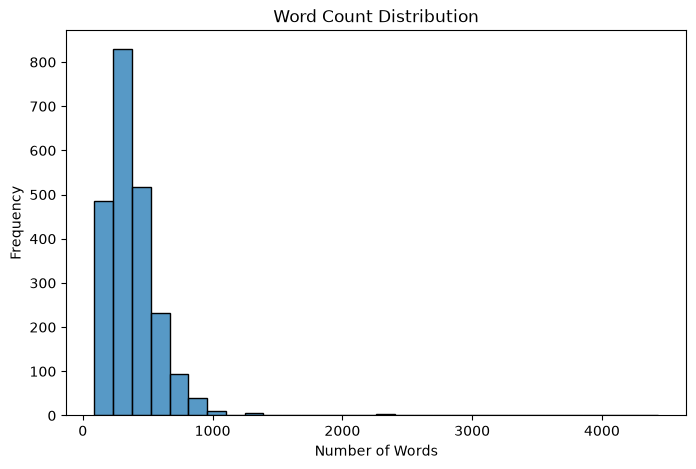

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Word_Count"], bins=30)

plt.title("Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

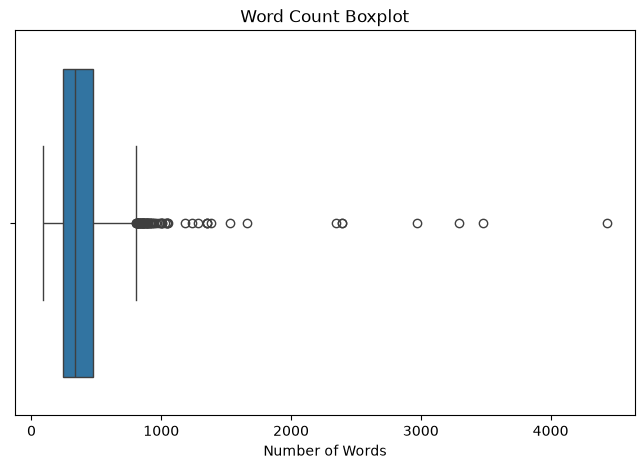

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Word_Count"])

plt.title("Word Count Boxplot")
plt.xlabel("Number of Words")

plt.show()

## 6. Data Quality Analysis

Check the dataset for duplicates, empty text, and whitespace issues.

In [21]:
duplicate_rows = df.duplicated().sum()
duplicate_texts = df["Text"].duplicated().sum()

print("Duplicate Rows:", duplicate_rows)
print("Duplicate Texts:", duplicate_texts)

Duplicate Rows: 98
Duplicate Texts: 98


In [22]:
duplicate_data = df[df.duplicated(keep=False)]

duplicate_data.head(10)

,Text,Label,Character_Length,Word_Count
2,Howard denies split over ID cards\n \n Michael...,0,3167,540
8,Fox attacks Blair's Tory 'lies'\n \n Tony Blai...,0,3002,514
33,Blair backs 'pre-election budget'\n \n Tony Bl...,0,2873,483
59,Blair backs 'pre-election budget'\n \n Tony Bl...,0,2873,483
68,'Debate needed' on donations cap\n \n A cap on...,0,3021,514
72,MPs issued with Blackberry threat\n \n MPs wil...,0,966,162
89,Kennedy questions trust of Blair\n \n Lib Dem ...,0,1927,358
100,Blair dismisses quit claim report\n \n Tony Bl...,0,3648,625
137,Brown ally rejects Budget spree\n \n Chancello...,0,2874,504
155,'Debate needed' on donations cap\n \n A cap on...,0,3021,514


In [23]:
empty_texts = df["Text"].eq("").sum()

whitespace_texts = df["Text"].str.strip().eq("").sum()

leading_trailing_spaces = (
    df["Text"] != df["Text"].str.strip()
).sum()

print("Empty Texts:", empty_texts)
print("Whitespace Only Texts:", whitespace_texts)
print("Leading or Trailing Spaces:", leading_trailing_spaces)

Empty Texts: 0
Whitespace Only Texts: 0
Leading or Trailing Spaces: 2225


In [24]:
text_types = df["Text"].apply(type).value_counts()

text_types

Text
<class 'str'>    2225
Name: count, dtype: int64

## 7. Text Noise Analysis

Identify URLs, HTML tags, numbers, and special characters in the text.

In [25]:
url_pattern = r"https?://\S+|www\.\S+"

html_pattern = r"<[^>]+>"

urls_count = df["Text"].str.contains(
    url_pattern, regex=True, na=False
).sum()

html_count = df["Text"].str.contains(
    html_pattern, regex=True, na=False
).sum()

print("Documents with URLs:", urls_count)
print("Documents with HTML:", html_count)

Documents with URLs: 3
Documents with HTML: 0


In [26]:
documents_with_numbers = df["Text"].str.contains(
    r"\d", regex=True, na=False
).sum()

documents_with_special_chars = df["Text"].str.contains(
    r"[^a-zA-Z0-9\s]", regex=True, na=False
).sum()

print("Documents with Numbers:", documents_with_numbers)
print("Documents with Special Characters:", documents_with_special_chars)

Documents with Numbers: 2116
Documents with Special Characters: 2225


In [41]:
print("Sample text:")
print(df["Text"].iloc[0][:1000])

Sample text:
Budget to set scene for election
 
 Gordon Brown will seek to put the economy at the centre of Labour's bid for a third term in power when he delivers his ninth Budget at 1230 GMT. He is expected to stress the importance of continued economic stability, with low unemployment and interest rates. The chancellor is expected to freeze petrol duty and raise the stamp duty threshold from Â£60,000. But the Conservatives and Lib Dems insist voters face higher taxes and more means-testing under Labour.
 
 Treasury officials have said there will not be a pre-election giveaway, but Mr Brown is thought to have about Â£2bn to spare.
 
 - Increase in the stamp duty threshold from Â£60,000 
  - A freeze on petrol duty 
  - An extension of tax credit scheme for poorer families 
  - Possible help for pensioners The stamp duty threshold rise is intended to help first time buyers - a likely theme of all three of the main parties' general election manifestos. Ten years ago, buyers had a much 

## 8. Language Detection

Detect the language of each document and analyze the language distribution.

In [42]:
def detect_language(text: str) -> str:
    """
    Detect the language of a text.

    Args:
        text: Input text.

    Returns:
        Detected language code or 'unknown'.
    """
    if not isinstance(text, str) or not text.strip():
        return "unknown"

    try:
        return detect(text)
    except Exception:
        return "unknown"

In [76]:
df["Language"] = df["Text"].apply(detect_language)

df["Language"].value_counts()

Language
en    2225
Name: count, dtype: int64

## 9. spaCy Setup



In [47]:
nlp= spacy.load("en_core_web_sm")


## 10. Tokenization

Tokenization is the process of splitting text into smaller units called tokens.

In [48]:
def tokenize_text(text: str) -> list[str]:
    """
    Split English text into tokens using spaCy.
    """
    if not isinstance(text, str):
        return []

    doc = nlp(text.lower())

    return [
        token.text
        for token in doc
        if not token.is_space
    ]


df["Tokens"] = df["Text"].apply(tokenize_text)

df[["Text", "Tokens"]].head()

,Text,Tokens
0,Budget to set scene for election\n \n Gordon B...,"[budget, to, set, scene, for, election, gordon..."
1,Army chiefs in regiments decision\n \n Militar...,"[army, chiefs, in, regiments, decision, milita..."
2,Howard denies split over ID cards\n \n Michael...,"[howard, denies, split, over, i, d, cards, mic..."
3,Observers to monitor UK election\n \n Minister...,"[observers, to, monitor, uk, election, ministe..."
4,Kilroy names election seat target\n \n Ex-chat...,"[kilroy, names, election, seat, target, ex, -,..."


## 11. Stop Words Removal

Stop words are common words that may carry limited information for some text analysis tasks.

In [49]:
def remove_stop_words(tokens: list[str]) -> list[str]:
    """
    Remove English stop words from a list of tokens.
    """
    return [
        token
        for token in tokens
        if token.lower() not in nlp.Defaults.stop_words
    ]


df["Tokens_No_Stopwords"] = df["Tokens"].apply(remove_stop_words)

df[["Tokens", "Tokens_No_Stopwords"]].head()

,Tokens,Tokens_No_Stopwords
0,"[budget, to, set, scene, for, election, gordon...","[budget, set, scene, election, gordon, brown, ..."
1,"[army, chiefs, in, regiments, decision, milita...","[army, chiefs, regiments, decision, military, ..."
2,"[howard, denies, split, over, i, d, cards, mic...","[howard, denies, split, d, cards, michael, how..."
3,"[observers, to, monitor, uk, election, ministe...","[observers, monitor, uk, election, ministers, ..."
4,"[kilroy, names, election, seat, target, ex, -,...","[kilroy, names, election, seat, target, ex, -,..."


## 12. Lemmatization

Lemmatization converts words into their base or dictionary form.

In [50]:
def lemmatize_text(text: str) -> list[str]:
    """
    Convert English words into their dictionary forms.
    """
    if not isinstance(text, str):
        return []

    doc = nlp(text.lower())

    return [
        token.lemma_
        for token in doc
        if not token.is_punct and not token.is_space
    ]


df["Lemmatized_Text"] = df["Text"].apply(lemmatize_text)

df[["Text", "Lemmatized_Text"]].head()

,Text,Lemmatized_Text
0,Budget to set scene for election\n \n Gordon B...,"[budget, to, set, scene, for, election, gordon..."
1,Army chiefs in regiments decision\n \n Militar...,"[army, chiefs, in, regiment, decision, militar..."
2,Howard denies split over ID cards\n \n Michael...,"[howard, deny, split, over, i, d, card, michae..."
3,Observers to monitor UK election\n \n Minister...,"[observer, to, monitor, uk, election, minister..."
4,Kilroy names election seat target\n \n Ex-chat...,"[kilroy, name, election, seat, target, ex, cha..."


In [52]:
df[["Text", "Lemmatized_Text"]].tail(10)

,Text,Lemmatized_Text
2215,Banker loses sexism claim\n \n A former execut...,"[banker, lose, sexism, claim, a, former, execu..."
2216,EC calls truce in deficit battle\n \n The Euro...,"[ec, call, truce, in, deficit, battle, the, eu..."
2217,Japanese growth grinds to a halt\n \n Growth i...,"[japanese, growth, grind, to, a, halt, growth,..."
2218,Tate & Lyle boss bags top award\n \n Tate & Ly...,"[tate, lyle, boss, bag, top, award, tate, lyle..."
2219,Stock market eyes Japan recovery\n \n Japanese...,"[stock, market, eye, japan, recovery, japanese..."
2220,India opens skies to competition\n \n India wi...,"[india, open, sky, to, competition, india, wil..."
2221,Yukos bankruptcy 'not US matter'\n \n Russian ...,"[yukos, bankruptcy, not, we, matter, russian, ..."
2222,Survey confirms property slowdown\n \n Governm...,"[survey, confirm, property, slowdown, governme..."
2223,High fuel prices hit BA's profits\n \n British...,"[high, fuel, price, hit, ba, 's, profit, briti..."
2224,US trade gap hits record in 2004\n \n The gap ...,"[us, trade, gap, hit, record, in, 2004, the, g..."


## 13. Regular Expressions

Regular expressions are used to find and replace text patterns.

In [54]:
def remove_urls(text: str) -> str:
    """
    Remove URLs from text.

    Args:
        text: Input text.

    Returns:
        Text without URLs.
    """
    return re.sub(r"https?://\S+|www\.\S+", "", text)

In [56]:
def remove_html_tags(text: str) -> str:
    """
    Remove HTML tags from text.

    Args:
        text: Input text.

    Returns:
        Text without HTML tags.
    """
    return re.sub(r"<[^>]+>", "", text)

In [57]:
def normalize_whitespace(text: str) -> str:
    """
    Replace repeated whitespace with a single space.

    Args:
        text: Input text.

    Returns:
        Text with normalized whitespace.
    """
    return re.sub(r"\s+", " ", text).strip()

In [78]:
def remove_emails(text: str) -> str:
    """
    Remove email addresses from text.

    Args:
        text: Input text.

    Returns:
        Text without email addresses.
    """
    return re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "",
        text
    )

## 14. Text Cleaning Functions v1

Create reusable functions to clean English text.

In [79]:
def clean_text(text: str) -> str:
    """
    Clean English text by removing URLs, HTML tags,
    email addresses, punctuation, and extra whitespace.
    Then apply lowercasing, lemmatization, and stop word removal.

    Args:
        text: Input English text.

    Returns:
        Cleaned text.
    """
    if not isinstance(text, str):
        return ""

    # Remove unwanted patterns
    text = remove_urls(text)
    text = remove_html_tags(text)
    text = remove_emails(text)

    # Normalize whitespace
    text = normalize_whitespace(text)

    # Remove punctuation
    text = re.sub(r"[^\w\s]", " ", text)
    text = normalize_whitespace(text)

    # Process text using spaCy
    doc = nlp(text.lower())

    # Preserve important negation words
    important_words = {"no", "not", "never"}

    tokens = [
        token.lemma_
        for token in doc
        if not token.is_punct
        and not token.is_space
        and (
            not token.is_stop
            or token.lower_ in important_words
        )
    ]

    return " ".join(tokens)


df["clean_text"] = df["Text"].apply(clean_text)

df[["Text", "clean_text"]].head()

,Text,clean_text
0,Budget to set scene for election\n \n Gordon B...,budget set scene election gordon brown seek ec...
1,Army chiefs in regiments decision\n \n Militar...,army chiefs regiment decision military chief e...
2,Howard denies split over ID cards\n \n Michael...,howard deny split d card michael howard deny s...
3,Observers to monitor UK election\n \n Minister...,observer monitor uk election minister invite i...
4,Kilroy names election seat target\n \n Ex-chat...,kilroy name election seat target ex chat host ...


## 15. Before and After Comparison

Compare the original text with the cleaned text.

In [74]:
for i in range(3):
  print("Original Text:")
  print(str(df.iloc[i]["Text"])[:500])

  print("\nCleaned Text:")
  print(str(df.iloc[i]["clean_text"])[:500])

  print("\n" + "-" * 60)

Original Text:
Budget to set scene for election
 
 Gordon Brown will seek to put the economy at the centre of Labour's bid for a third term in power when he delivers his ninth Budget at 1230 GMT. He is expected to stress the importance of continued economic stability, with low unemployment and interest rates. The chancellor is expected to freeze petrol duty and raise the stamp duty threshold from Â£60,000. But the Conservatives and Lib Dems insist voters face higher taxes and more means-testing under Labour.
 

Cleaned Text:
budget set scene election gordon brown seek economy centre labour s bid term power deliver ninth budget 1230 gmt expect stress importance continue economic stability low unemployment interest rate chancellor expect freeze petrol duty raise stamp duty threshold â 60 000 conservative lib dem insist voter face high taxis mean test labour treasury official say pre election giveaway mr brown think â 2bn spare increase stamp duty threshold â 60 000 freeze petrol duty ext

In [75]:
print(df.columns.tolist())

['Text', 'Label', 'Character_Length', 'Word_Count', 'Language', 'Tokens', 'Tokens_No_Stopwords', 'Lemmatized_Text', 'clean_text']


## 16. Testing the Cleaning Function

Test the cleaning function using different text examples
to verify that it handles common text patterns correctly.

In [82]:
test_examples = [
    "I am RUNNING and playing football!",
    "Visit https://example.com for more information.",
    "<p>This is a sample HTML text.</p>",
    "   This    sentence   has    extra spaces!!!   "
]

for example in test_examples:
    print("Original:", example)
    print("Cleaned:", clean_text(example))
    print("-" * 60)

Original: I am RUNNING and playing football!
Cleaned: run play football
------------------------------------------------------------
Original: Visit https://example.com for more information.
Cleaned: visit information
------------------------------------------------------------
Original: <p>This is a sample HTML text.</p>
Cleaned: sample html text
------------------------------------------------------------
Original:    This    sentence   has    extra spaces!!!   
Cleaned: sentence extra space
------------------------------------------------------------


In [81]:
# Basic validation tests

assert clean_text("") == ""
assert clean_text(None) == ""

assert "not" in clean_text("This is not good.")

assert "https://" not in clean_text(
    "Visit https://example.com"
)

assert "test@example.com" not in clean_text(
    "Contact test@example.com"
)

print("All basic tests passed!")

All basic tests passed!


## 17. Cleaned Data Quality Check

Check the cleaned text to identify empty documents and review the final results.

In [83]:
empty_cleaned_texts = df["clean_text"].str.strip().eq("").sum()

print("Total documents:", len(df))
print("Empty cleaned documents:", empty_cleaned_texts)
print("Non-empty cleaned documents:", len(df) - empty_cleaned_texts)

Total documents: 2225
Empty cleaned documents: 0
Non-empty cleaned documents: 2225


In [84]:
df[["Text", "clean_text"]].sample(5, random_state=42)

,Text,clean_text
414,David Blunkett in quotes\n \n David Blunkett -...,david blunkett quotes david blunkett resign ho...
420,Benitez issues warning to Gerrard\n \n Liverpo...,benitez issue warn gerrard liverpool manager r...
1644,Brookside creator's Channel 4 bid\n \n The cre...,brookside creator s channel 4 bid creator defu...
416,Brown visits slum on Africa trip\n \n Chancell...,brown visit slum africa trip chancellor gordon...
1232,Gritty return for Prince of Persia\n \n Still ...,gritty return prince persia bask relatively re...


## 18. Research Note: Text Cleaning

### 1. How do practitioners clean text?

Text cleaning is an important step in Natural Language Processing (NLP). Practitioners use several techniques to prepare raw text for further analysis.

In this notebook, the following techniques were applied:

- **Tokenization:** Splitting text into smaller units called tokens using spaCy.
- **Stop Words Removal:** Removing common words that may not provide useful information for some tasks.
- **Lemmatization:** Converting words into their base or dictionary forms.
- **Regular Expressions (Regex):** Removing URLs, HTML tags, and unnecessary whitespace.
- **Lowercasing:** Converting all text to lowercase to maintain consistency.
- **Punctuation Removal:** Removing punctuation marks from the text.

### 2. What can go wrong during text cleaning?

Text cleaning can introduce problems if it is not performed carefully.

Some possible problems include:

- **Loss of Meaning:** Removing words such as "not" or "never" may change the meaning of a sentence.
- **Over-cleaning:** Removing too much information may affect the quality of the text.
- **Language Detection Errors:** Short or unclear texts may be classified incorrectly.
- **Encoding Problems:** Special characters may appear incorrectly when text is loaded using an unsuitable encoding.
- **Lemmatization Errors:** Some words may not be converted into the intended base form.

### 3. Dataset Results

The dataset contains 2,225 documents.

Language detection showed that all 2,225 documents were English, with zero non-English documents.

The notebook applied tokenization, stop words removal, lemmatization, regular expressions, and a combined text cleaning function.

### 4. Conclusion

Text cleaning helps improve text consistency and prepares documents for further NLP tasks. However, cleaning decisions should be selected carefully because removing certain words or characters may result in losing important information.